<a href="https://colab.research.google.com/github/pedrosampaiom2007-gif/pandas/blob/main/notebooks/02_limpeza_e_tratamento_de_dados_churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PRÁTICA

In [44]:
# Praticando normalização
import json

In [45]:
import pandas as pd

In [46]:
import numpy as np

In [47]:
with open('informacoes.json') as f:
  correcao=json.load(f)# esse codigo serve pra carregar o arquivo todo

In [48]:
pd.json_normalize(correcao,record_path='enderecos',meta=['nome','idade'])

#O primeiro parametro é a base de dados que vai ser normalizada, O record path(segundo parametro) indica o que será normalizado no data frame indicado no 1 parametro, o meta indica oq vai ser mantido da mesma forma

,tipo,rua,numero,cidade,nome,idade
0,casa,Rua A,123,São Paulo,João,28
1,trabalho,Rua B,456,Rio de Janeiro,João,28


# Removendo dados vazios e arrumando tipagem das colunas



In [49]:
pd.read_json('/content/dados_pratica.json')

,pessoas
0,"{'nome': 'João', 'idade': '25', 'endereco': {'..."
1,"{'nome': 'Maria', 'idade': 30, 'endereco': {'r..."


In [50]:
with open('/content/dados_pratica.json') as f:
  json_resolvido=json.load(f)

In [51]:
praticado=pd.json_normalize(json_resolvido,record_path='pessoas')
praticado

,nome,idade,telefones,endereco.rua,endereco.numero,endereco.cidade
0,João,25,"[11 1111-1111, 11 2222-2222]",Rua A,123,São Paulo
1,Maria,30,[21 3333-3333],,456,Rio de Janeiro


In [52]:
praticado.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   nome             2 non-null      object
 1   idade            2 non-null      object
 2   telefones        2 non-null      object
 3   endereco.rua     2 non-null      object
 4   endereco.numero  2 non-null      int64 
 5   endereco.cidade  2 non-null      object
dtypes: int64(1), object(5)
memory usage: 228.0+ bytes


In [53]:
praticado['idade']=praticado['idade'].astype(int)

In [54]:
praticado_novo= praticado[praticado['endereco.rua']!='']
praticado_novo


,nome,idade,telefones,endereco.rua,endereco.numero,endereco.cidade
0,João,25,"[11 1111-1111, 11 2222-2222]",Rua A,123,São Paulo


#Removendo dados nulos e vazios, treinando com tipagem de dados_etc...

In [55]:
dados_P=pd.read_json('/content/cursos_cadastrados.json')

In [56]:
with open('/content/cursos_cadastrados.json') as f:
  json_curso= json.load(f)


In [57]:
dados_P_normal=pd.json_normalize(json_curso)
dados_P_normal

,curso,categoria,carga_horaria,concluintes,data_inicio,data_conclusao,descricao,preco,instrutor.nome,instrutor.email,instrutor.telefone
0,Introdução à programação,Programação,20 horas,100,2022-01-01,2022-01-20,Curso introdutório à programação com Python,99.90,João Silva,joao.silva@emailaleatorio.com,(11) 9999-9999
1,Excel para iniciantes,Produtividade,None,None,None,None,None,None,Maria Oliveira,maria.oliveira@emailaleatorio.com,(11) 8888-8888
2,Marketing digital para negócios,Marketing,30 horas,75,2022-03-01,2022-03-31,Curso introdutório em marketing,89.9,Ana Santos,ana.santos@emailaleatorio.com,(11) 7777-7777
3,Inteligência artificial,Programação,40 horas,,2022-04-01,,Curso avançado sobre inteligência artificial c...,129.9,,contato@emailaleatorio.com,
4,Inglês para negócios,Idiomas,20 horas,30,,,Curso de inglês para negócios,69.9,John Smith,,
5,Introdução à programação,Programação,20 horas,100,2022-01-01,2022-01-20,Curso introdutório à programação com Python,99.90,João Silva,joao.silva@emailaleatorio.com,(11) 9999-9999


In [58]:
dados_P_normal.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   curso               6 non-null      object
 1   categoria           6 non-null      object
 2   carga_horaria       5 non-null      object
 3   concluintes         5 non-null      object
 4   data_inicio         5 non-null      object
 5   data_conclusao      5 non-null      object
 6   descricao           5 non-null      object
 7   preco               5 non-null      object
 8   instrutor.nome      6 non-null      object
 9   instrutor.email     6 non-null      object
 10  instrutor.telefone  6 non-null      object
dtypes: object(11)
memory usage: 660.0+ bytes


In [59]:
dados_P_normal.isna().sum()# tratando dados nulos


,0
curso,0
categoria,0
carga_horaria,1
concluintes,1
data_inicio,1
data_conclusao,1
descricao,1
preco,1
instrutor.nome,0
instrutor.email,0


In [60]:
dados_P_normal[dados_P_normal.eq('').any(axis=1)]

,curso,categoria,carga_horaria,concluintes,data_inicio,data_conclusao,descricao,preco,instrutor.nome,instrutor.email,instrutor.telefone
3,Inteligência artificial,Programação,40 horas,,2022-04-01,,Curso avançado sobre inteligência artificial c...,129.9,,contato@emailaleatorio.com,
4,Inglês para negócios,Idiomas,20 horas,30,,,Curso de inglês para negócios,69.9,John Smith,,


In [61]:
colunas_vazio=dados_P_normal.columns[dados_P_normal.eq('').any(axis=0)]
colunas_vazio

Index(['concluintes', 'data_inicio', 'data_conclusao', 'instrutor.nome',
       'instrutor.email', 'instrutor.telefone'],
      dtype='object')

In [62]:
dados_P_normal.replace('',np.nan,inplace=True)

/tmp/ipykernel_1772/1472775194.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dados_P_normal.replace('',np.nan,inplace=True)


In [63]:
# 1. Definimos a lista de colunas corretamente usando uma lista de strings []
colunas_vazias = [
    'concluintes', 'data_inicio', 'data_conclusao',
    'instrutor.nome', 'instrutor.email', 'instrutor.telefone'
]

# 2. Agora removemos as linhas nulas com base apenas nessas colunas, usando o DataFrame correto
dados_P_normal.dropna(subset=colunas_vazias, inplace=True)

# Vamos ver como ficou o resultado final limpo
dados_P_normal

,curso,categoria,carga_horaria,concluintes,data_inicio,data_conclusao,descricao,preco,instrutor.nome,instrutor.email,instrutor.telefone
0,Introdução à programação,Programação,20 horas,100.0,2022-01-01,2022-01-20,Curso introdutório à programação com Python,99.90,João Silva,joao.silva@emailaleatorio.com,(11) 9999-9999
2,Marketing digital para negócios,Marketing,30 horas,75.0,2022-03-01,2022-03-31,Curso introdutório em marketing,89.9,Ana Santos,ana.santos@emailaleatorio.com,(11) 7777-7777
5,Introdução à programação,Programação,20 horas,100.0,2022-01-01,2022-01-20,Curso introdutório à programação com Python,99.90,João Silva,joao.silva@emailaleatorio.com,(11) 9999-9999


In [64]:
dados_P_normal.drop_duplicates(inplace=True)

In [65]:
dados_P_normal.isna().sum()

,0
curso,0
categoria,0
carga_horaria,0
concluintes,0
data_inicio,0
data_conclusao,0
descricao,0
preco,0
instrutor.nome,0
instrutor.email,0


In [66]:
dados_P_normal

,curso,categoria,carga_horaria,concluintes,data_inicio,data_conclusao,descricao,preco,instrutor.nome,instrutor.email,instrutor.telefone
0,Introdução à programação,Programação,20 horas,100.0,2022-01-01,2022-01-20,Curso introdutório à programação com Python,99.90,João Silva,joao.silva@emailaleatorio.com,(11) 9999-9999
2,Marketing digital para negócios,Marketing,30 horas,75.0,2022-03-01,2022-03-31,Curso introdutório em marketing,89.9,Ana Santos,ana.santos@emailaleatorio.com,(11) 7777-7777


In [67]:
# Alterando os tipos de dado para data
dados_P_normal['data_inicio']=pd.to_datetime(dados_P_normal['data_inicio'])
dados_P_normal['data_conclusao']=pd.to_datetime(dados_P_normal['data_conclusao'])


In [68]:
# Alterando pra int e float
dados_P_normal['concluintes'].astype(int)


,concluintes
0,100
2,75


In [69]:
dados_P_normal['preco'].astype(float)

,preco
0,99.9
2,89.9


In [70]:
dados_P_normal.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2 entries, 0 to 2
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   curso               2 non-null      object        
 1   categoria           2 non-null      object        
 2   carga_horaria       2 non-null      object        
 3   concluintes         2 non-null      float64       
 4   data_inicio         2 non-null      datetime64[ns]
 5   data_conclusao      2 non-null      datetime64[ns]
 6   descricao           2 non-null      object        
 7   preco               2 non-null      object        
 8   instrutor.nome      2 non-null      object        
 9   instrutor.email     2 non-null      object        
 10  instrutor.telefone  2 non-null      object        
dtypes: datetime64[ns](2), float64(1), object(8)
memory usage: 300.0+ bytes


# Tratando outliers, exercícios

In [71]:
def calc_outliers(column, dataframe):

  # calculando o IQR e definindo o limite para outliers
  Q1 = dataframe[column].quantile(0.25)
  Q3 = dataframe[column].quantile(0.75)
  IQR = Q3 - Q1
  limite_inferior = Q1 - 1.5 * IQR
  limite_superior = Q3 + 1.5 * IQR

  # identificando os outliers
  outliers = dataframe[(dataframe[column] < limite_inferior) | (dataframe[column] > limite_superior)]

  # retornando os outliers
  return outliers

## EXERCÍCIOS DA AULA


### Guia Prático: Como Rastrear e Isolar Valores Nulos Específicos

##Churn é um termo utilizado para se referir à taxa de cancelamento de clientes em um determinado período de tempo. Em outras palavras, é a porcentagem de clientes que deixam de usar um produto ou serviço em um determinado período.


In [72]:
# Para ler este arquivo corretamente, primeiro carregamos com a biblioteca json
dados=pd.read_json('/content/dataset-telecon.json')

In [73]:
dados.head()

,id_cliente,Churn,cliente,telefone,internet,conta
0,0002-ORFBO,nao,"{'genero': 'feminino', 'idoso': 0, 'parceiro':...","{'servico_telefone': 'sim', 'varias_linhas': '...","{'servico_internet': 'DSL', 'seguranca_online'...","{'contrato': None, 'faturamente_eletronico': N..."
1,0003-MKNFE,nao,"{'genero': 'masculino', 'idoso': 0, 'parceiro'...","{'servico_telefone': 'sim', 'varias_linhas': '...","{'servico_internet': 'DSL', 'seguranca_online'...","{'contrato': 'mes a mes', 'faturamente_eletron..."
2,0004-TLHLJ,sim,"{'genero': 'masculino', 'idoso': 0, 'parceiro'...","{'servico_telefone': 'sim', 'varias_linhas': '...","{'servico_internet': 'fibra otica', 'seguranca...","{'contrato': 'mes a mes', 'faturamente_eletron..."
3,0011-IGKFF,sim,"{'genero': 'masculino', 'idoso': 1, 'parceiro'...","{'servico_telefone': 'sim', 'varias_linhas': '...","{'servico_internet': 'fibra otica', 'seguranca...","{'contrato': 'mes a mes', 'faturamente_eletron..."
4,0013-EXCHZ,sim,"{'genero': 'feminino', 'idoso': 1, 'parceiro':...","{'servico_telefone': 'sim', 'varias_linhas': '...","{'servico_internet': 'fibra otica', 'seguranca...","{'contrato': 'mes a mes', 'faturamente_eletron..."


In [74]:
# Normalizanod os dados de apenas uma coluna

pd.json_normalize(dados['conta'])


,contrato,faturamente_eletronico,metodo_pagamento,cobranca.mensal,cobranca.Total
0,None,None,None,NaN,None
1,mes a mes,nao,cheque pelo correio,59.90,542.4
2,mes a mes,sim,cheque eletronico,73.90,280.85
3,mes a mes,sim,cheque eletronico,98.00,1237.85
4,mes a mes,sim,cheque pelo correio,83.90,267.4
...,...,...,...,...,...
7339,dois anos,sim,cartao de credito (automatico),108.95,7875
7340,um ano,nao,cartao de credito (automatico),20.10,620.55
7341,mes a mes,sim,cartao de credito (automatico),96.15,3019.25
7342,um ano,nao,transferencia bancaria (automatica),19.50,798.2


In [75]:
#Transformando dados em uma tabela normalizanod de uma vez só
import json

In [76]:
# usando with pra abrir um arquivo e garantir que ele será fechado após  a execução, as nomeia como f
with open('dataset-telecon.json') as f:
    json_bruto=json.load(f)

In [77]:
dados_normalizados=pd.json_normalize(json_bruto)

### O método `json_normalize()`

O método `json_normalize()` é usado para normalizar dados JSON em um formato tabular (como um DataFrame do Pandas) para facilitar a análise e manipulação. Os parâmetros mais importantes são:

* **`data`**: O objeto JSON a ser normalizado.
* **`record_path`**: Um caminho para acessar o array de registros dentro do objeto JSON.
* **`meta`**: Uma lista de colunas adicionais a serem incluídas no DataFrame, além das colunas normalizadas.
* **`errors`**: Como lidar com erros de normalização. Os valores possíveis são:
  * `"raise"` (lançar um erro)
  * `"ignore"` (ignorar o erro)
* **`sep`**: Separador de colunas usado para concatenar as chaves do objeto JSON aninhado. O padrão é `"."`.

In [78]:
# Exemplo:
import pandas as pd

data = {
    "empresa": "alura",
    "funcionarios": [
        {"nome": "Alice", "endereço": {"cidade": "São Paulo", "estado": "SP"}},
        {"nome": "Bob", "endereço": {"cidade": "Rio de Janeiro", "estado": "RJ"}}
    ]
}

df = pd.json_normalize(data, record_path='funcionarios', meta = "empresa", errors='ignore')

In [79]:
dados_normalizados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7344 entries, 0 to 7343
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_cliente                     7344 non-null   object 
 1   Churn                          7344 non-null   object 
 2   cliente.genero                 7344 non-null   object 
 3   cliente.idoso                  7344 non-null   int64  
 4   cliente.parceiro               7344 non-null   object 
 5   cliente.dependentes            7344 non-null   object 
 6   cliente.tempo_servico          7336 non-null   float64
 7   telefone.servico_telefone      7344 non-null   object 
 8   telefone.varias_linhas         7344 non-null   object 
 9   internet.servico_internet      7344 non-null   object 
 10  internet.seguranca_online      7344 non-null   object 
 11  internet.backup_online         7344 non-null   object 
 12  internet.protecao_dispositivo  7344 non-null   o

In [80]:
dados_normalizados['conta.cobranca.Total'][dados_normalizados['conta.cobranca.Total' ]== ''].head()

,conta.cobranca.Total


In [81]:
dados_normalizados[dados_normalizados['conta.cobranca.Total'] == ' '][

    ['cliente.tempo_servico', 'conta.contrato', 'conta.cobranca.mensal', 'conta.cobranca.Total']
]

,cliente.tempo_servico,conta.contrato,conta.cobranca.mensal,conta.cobranca.Total
975,0.0,dois anos,56.05,
1775,0.0,dois anos,20.00,
1955,0.0,dois anos,61.90,
2075,0.0,dois anos,19.70,
2232,0.0,dois anos,20.25,
2308,0.0,dois anos,25.35,
2930,0.0,dois anos,73.35,
3134,0.0,dois anos,25.75,
3203,0.0,dois anos,52.55,
4169,0.0,dois anos,80.85,


In [82]:
idx=dados_normalizados[dados_normalizados['conta.cobranca.Total'] == ' '].index# encontrando os dados vazios '  '


In [83]:
dados_normalizados.loc[idx,'conta.cobranca.Total']= dados_normalizados.loc[idx,'conta.cobranca.mensal']*24 # preenchendo dados  vazios ' '

In [84]:
dados_normalizados.loc[idx, "cliente.tempo_servico"] = 24

In [85]:
dados_normalizados.loc[idx][

['cliente.tempo_servico', 'conta.contrato', 'conta.cobranca.mensal', 'conta.cobranca.Total']
]

,cliente.tempo_servico,conta.contrato,conta.cobranca.mensal,conta.cobranca.Total
975,24.0,dois anos,56.05,1345.2
1775,24.0,dois anos,20.00,480.0
1955,24.0,dois anos,61.90,1485.6
2075,24.0,dois anos,19.70,472.8
2232,24.0,dois anos,20.25,486.0
2308,24.0,dois anos,25.35,608.4
2930,24.0,dois anos,73.35,1760.4
3134,24.0,dois anos,25.75,618.0
3203,24.0,dois anos,52.55,1261.2
4169,24.0,dois anos,80.85,1940.4


In [86]:
dados_normalizados['conta.cobranca.Total']=dados_normalizados['conta.cobranca.Total'].astype(np.float64)# Trocando o tipo de dado

# Identificando e tratando strings vazias

In [87]:
for col in dados_normalizados.columns:
  print(f"Coluna: {col}")
  print(dados_normalizados[col].unique())
  print("-" * 30)


Coluna: id_cliente
['0002-ORFBO' '0003-MKNFE' '0004-TLHLJ' ... '9992-UJOEL' '9993-LHIEB'
 '9995-HOTOH']
------------------------------
Coluna: Churn
['nao' 'sim' '']
------------------------------
Coluna: cliente.genero
['feminino' 'masculino']
------------------------------
Coluna: cliente.idoso
[0 1]
------------------------------
Coluna: cliente.parceiro
['sim' 'nao']
------------------------------
Coluna: cliente.dependentes
['sim' 'nao']
------------------------------
Coluna: cliente.tempo_servico
[9.00e+00 4.00e+00 1.30e+01 3.00e+00 7.10e+01 6.30e+01 7.00e+00      nan
 5.40e+01 7.20e+01 5.00e+00 5.60e+01 3.40e+01 1.00e+00 4.50e+01 5.00e+01
 2.30e+01 5.50e+01 2.60e+01 6.90e+01 1.10e+01 3.70e+01 4.90e+01 6.60e+01
 6.70e+01 2.00e+01 4.30e+01 5.90e+01 1.20e+01 2.70e+01 2.00e+00 2.50e+01
 2.90e+01 1.40e+01 3.50e+01 6.40e+01 3.90e+01 4.00e+01 6.00e+00 3.00e+01
 7.00e+01 5.70e+01 5.80e+01 1.60e+01 3.20e+01 3.30e+01 1.00e+01 2.10e+01
 6.10e+01 1.50e+01 4.40e+01 2.20e+01 2.40e+01 1.90e+01

In [88]:
dados_normalizados.query("Churn == ''") # buscando valores específicos no caso vazios, na base de dados com query

,id_cliente,Churn,cliente.genero,cliente.idoso,cliente.parceiro,cliente.dependentes,cliente.tempo_servico,telefone.servico_telefone,telefone.varias_linhas,internet.servico_internet,...,internet.backup_online,internet.protecao_dispositivo,internet.suporte_tecnico,internet.tv_streaming,internet.filmes_streaming,conta.contrato,conta.faturamente_eletronico,conta.metodo_pagamento,conta.cobranca.mensal,conta.cobranca.Total
30,0047-ZHDTW,,feminino,0,nao,nao,11.0,sim,sim,fibra otica,...,nao,nao,nao,nao,nao,mes a mes,sim,transferencia bancaria (automatica),79.00,929.30
75,0120-YZLQA,,masculino,0,nao,nao,71.0,sim,nao,nao,...,sem servico de internet,sem servico de internet,sem servico de internet,sem servico de internet,sem servico de internet,dois anos,sim,cartao de credito (automatico),19.90,1355.10
96,0154-QYHJU,,masculino,0,nao,nao,29.0,sim,nao,DSL,...,sim,nao,sim,nao,nao,um ano,sim,cheque eletronico,58.75,1696.20
98,0162-RZGMZ,,feminino,1,nao,nao,5.0,sim,nao,DSL,...,sim,nao,sim,nao,nao,mes a mes,nao,cartao de credito (automatico),59.90,287.85
175,0274-VVQOQ,,masculino,1,sim,nao,65.0,sim,sim,fibra otica,...,sim,sim,nao,sim,sim,um ano,sim,transferencia bancaria (automatica),103.15,6792.45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7211,9920-GNDMB,,masculino,0,nao,nao,9.0,sim,sim,fibra otica,...,nao,nao,nao,nao,nao,mes a mes,sim,cheque eletronico,76.25,684.85
7239,9955-RVWSC,,feminino,0,sim,sim,67.0,sim,nao,nao,...,sem servico de internet,sem servico de internet,sem servico de internet,sem servico de internet,sem servico de internet,dois anos,sim,transferencia bancaria (automatica),19.25,1372.90
7247,9966-VYRTZ,,feminino,0,sim,sim,31.0,sim,nao,nao,...,sem servico de internet,sem servico de internet,sem servico de internet,sem servico de internet,sem servico de internet,mes a mes,sim,cheque pelo correio,19.55,658.95
7267,6532-YOHZY,,masculino,0,sim,sim,45.0,sim,sim,fibra otica,...,sim,sim,sim,sim,sim,dois anos,sim,transferencia bancaria (automatica),109.75,4900.65


In [89]:
dados_sem_vazio=dados_normalizados[dados_normalizados['Churn']!= ''].copy() # Criando uma cópia com subconjunto dos dados sem os valores ''

In [90]:
dados_sem_vazio.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7118 entries, 0 to 7343
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_cliente                     7118 non-null   object 
 1   Churn                          7118 non-null   object 
 2   cliente.genero                 7118 non-null   object 
 3   cliente.idoso                  7118 non-null   int64  
 4   cliente.parceiro               7118 non-null   object 
 5   cliente.dependentes            7118 non-null   object 
 6   cliente.tempo_servico          7110 non-null   float64
 7   telefone.servico_telefone      7118 non-null   object 
 8   telefone.varias_linhas         7118 non-null   object 
 9   internet.servico_internet      7118 non-null   object 
 10  internet.seguranca_online      7118 non-null   object 
 11  internet.backup_online         7118 non-null   object 
 12  internet.protecao_dispositivo  7118 non-null   object

In [91]:
dados_sem_vazio.reset_index(drop=True,inplace=True)

# Tratando dados duplicados que é quando um dado da coluna A é igual ao da coluna B


In [92]:
# Usando o método duplicated, False quando não é duplicada e True quando é duplicada

dados_sem_vazio.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
7113,True
7114,True
7115,True
7116,True


In [93]:
# Para verificar quantos valores duplicados tem basta usar o .sum

dados_sem_vazio.duplicated().sum()

np.int64(75)

In [94]:
# Para descobrir onde estão as duplicadas:

filtro_duplicadas= dados_sem_vazio.duplicated()
dados_sem_vazio[filtro_duplicadas]

,id_cliente,Churn,cliente.genero,cliente.idoso,cliente.parceiro,cliente.dependentes,cliente.tempo_servico,telefone.servico_telefone,telefone.varias_linhas,internet.servico_internet,...,internet.backup_online,internet.protecao_dispositivo,internet.suporte_tecnico,internet.tv_streaming,internet.filmes_streaming,conta.contrato,conta.faturamente_eletronico,conta.metodo_pagamento,conta.cobranca.mensal,conta.cobranca.Total
7043,0675-NCDYU,nao,feminino,0,sim,sim,72.0,sim,sim,fibra otica,...,sim,sim,sim,sim,sim,dois anos,sim,cartao de credito (automatico),116.40,8543.25
7044,6754-LZUKA,nao,masculino,0,sim,nao,61.0,sim,sim,DSL,...,sim,sim,nao,sim,sim,dois anos,nao,transferencia bancaria (automatica),80.90,4932.50
7045,2192-CKRLV,nao,feminino,0,sim,nao,72.0,nao,sem servico de telefone,DSL,...,sim,sim,nao,nao,sim,dois anos,sim,cheque eletronico,49.20,3580.95
7046,9170-ARBTB,nao,feminino,0,sim,sim,52.0,sim,nao,nao,...,sem servico de internet,sem servico de internet,sem servico de internet,sem servico de internet,sem servico de internet,um ano,nao,cartao de credito (automatico),19.60,1012.40
7047,0447-BEMNG,sim,feminino,0,sim,nao,48.0,nao,sem servico de telefone,DSL,...,nao,sim,nao,nao,sim,mes a mes,sim,transferencia bancaria (automatica),45.30,2145.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7113,5792-JALQC,nao,feminino,1,nao,nao,52.0,sim,sim,DSL,...,nao,sim,nao,nao,nao,dois anos,nao,transferencia bancaria (automatica),59.85,3103.25
7114,5172-RKOCB,nao,masculino,0,sim,nao,72.0,sim,sim,fibra otica,...,sim,nao,sim,sim,sim,dois anos,sim,cartao de credito (automatico),108.95,7875.00
7115,1934-MKPXS,nao,masculino,0,sim,sim,33.0,sim,nao,nao,...,sem servico de internet,sem servico de internet,sem servico de internet,sem servico de internet,sem servico de internet,um ano,nao,cartao de credito (automatico),20.10,620.55
7116,5959-BELXA,sim,masculino,1,nao,nao,32.0,sim,sim,fibra otica,...,nao,nao,nao,sim,sim,mes a mes,sim,cartao de credito (automatico),96.15,3019.25


In [95]:
# Removendo amostras duplicadas, inplace=True pra fazer a mudança de forma defintiva

dados_sem_vazio.drop_duplicates(inplace=True)

# Tratando dados nulos

In [96]:
dados_sem_vazio.isna().sum() # Checando dados nulos se aparecer número é quantidade de dados nulos

,0
id_cliente,0
Churn,0
cliente.genero,0
cliente.idoso,0
cliente.parceiro,0
cliente.dependentes,0
cliente.tempo_servico,8
telefone.servico_telefone,0
telefone.varias_linhas,0
internet.servico_internet,0


In [97]:
dados_sem_vazio.isna().sum().sum()# dois sums pra somar o total do dataframe e nao somar por coluna

np.int64(114)

In [98]:
# Descobrindo como descobrir em quantas amostras diferentes possuem dados nulos, na outra vc via dados nulos na mesma amostra mais de um dado nulo no indice 0 exemplo
# o resultado vai ser que em x amostras tem pelo menos um valor nulo em uma das colunas

dados_sem_vazio[dados_sem_vazio.isna().any(axis=1)]

,id_cliente,Churn,cliente.genero,cliente.idoso,cliente.parceiro,cliente.dependentes,cliente.tempo_servico,telefone.servico_telefone,telefone.varias_linhas,internet.servico_internet,...,internet.backup_online,internet.protecao_dispositivo,internet.suporte_tecnico,internet.tv_streaming,internet.filmes_streaming,conta.contrato,conta.faturamente_eletronico,conta.metodo_pagamento,conta.cobranca.mensal,conta.cobranca.Total
0,0002-ORFBO,nao,feminino,0,sim,sim,9.0,sim,nao,DSL,...,sim,nao,sim,sim,nao,None,None,None,NaN,NaN
9,0016-QLJIS,nao,feminino,0,sim,sim,NaN,sim,sim,DSL,...,sim,sim,sim,sim,sim,dois anos,sim,cheque pelo correio,90.45,5957.90
176,0282-NVSJS,nao,feminino,1,sim,sim,NaN,nao,sem servico de telefone,DSL,...,nao,nao,sim,nao,nao,mes a mes,sim,cheque pelo correio,29.30,355.90
181,0295-QVKPB,nao,masculino,0,nao,nao,NaN,sim,nao,DSL,...,nao,sim,sim,sim,nao,mes a mes,sim,cartao de credito (automatico),63.95,318.10
437,0639-TSIQW,sim,feminino,0,nao,nao,67.0,sim,sim,fibra otica,...,sim,sim,nao,sim,nao,None,None,cartao de credito (automatico),NaN,6886.25
751,1095-WGNGG,nao,feminino,0,sim,nao,NaN,sim,sim,fibra otica,...,sim,nao,nao,sim,sim,dois anos,sim,transferencia bancaria (automatica),101.05,5971.25
963,1396-QWFBJ,sim,feminino,0,sim,sim,21.0,sim,nao,fibra otica,...,sim,nao,nao,nao,nao,None,sim,None,NaN,1565.70
1604,2333-KWEWW,nao,masculino,0,nao,nao,18.0,sim,nao,nao,...,sem servico de internet,sem servico de internet,sem servico de internet,sem servico de internet,sem servico de internet,None,nao,None,20.05,NaN
1605,2335-GSODA,nao,masculino,0,nao,sim,23.0,nao,sem servico de telefone,DSL,...,nao,sim,sim,nao,nao,None,nao,None,NaN,NaN
1606,2338-BQEZT,nao,feminino,0,nao,nao,55.0,sim,nao,DSL,...,nao,nao,nao,nao,nao,None,sim,cartao de credito (automatico),NaN,NaN


In [99]:
#Preenchendo valores nulos
filtro=dados_sem_vazio['cliente.tempo_servico'].isna()

In [100]:
dados_sem_vazio[filtro][['cliente.tempo_servico','conta.cobranca.mensal','conta.cobranca.Total']]

,cliente.tempo_servico,conta.cobranca.mensal,conta.cobranca.Total
9,NaN,90.45,5957.90
176,NaN,29.30,355.90
181,NaN,63.95,318.10
751,NaN,101.05,5971.25
3523,NaN,76.10,1054.80
5273,NaN,20.60,116.60
5276,NaN,73.85,3581.40
6134,NaN,69.05,1958.45


In [101]:
np.ceil(5957.90/90.45)

np.float64(66.0)

In [102]:
#Preenchendo valores nulos
dados_sem_vazio['cliente.tempo_servico'].fillna(
    np.ceil( dados_sem_vazio['conta.cobranca.Total'] / dados_sem_vazio['conta.cobranca.mensal']
    ), inplace=True)

/tmp/ipykernel_1772/1579935711.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dados_sem_vazio['cliente.tempo_servico'].fillna(


In [103]:
dados_sem_vazio[filtro][['cliente.tempo_servico','conta.cobranca.mensal','conta.cobranca.Total']]

,cliente.tempo_servico,conta.cobranca.mensal,conta.cobranca.Total
9,66.0,90.45,5957.90
176,13.0,29.30,355.90
181,5.0,63.95,318.10
751,60.0,101.05,5971.25
3523,14.0,76.10,1054.80
5273,6.0,20.60,116.60
5276,49.0,73.85,3581.40
6134,29.0,69.05,1958.45


# Removendo dados nulos

In [104]:
dados_sem_vazio['conta.contrato'].value_counts() # Contando os valores

,count
conta.contrato,
mes a mes,3861
dois anos,1688
um ano,1463


In [105]:
colunas_dropar=['conta.contrato',
'conta.faturamente_eletronico',
'conta.metodo_pagamento']# Colunas que vamos remover os valores nulos no dropna

In [106]:
dados_sem_vazio[colunas_dropar].isna().any(axis=1).sum()

np.int64(37)

In [107]:
# Retirando os dados nulos e criando uma cópia que nao interfere nos outros df

dados_sem_nulos=dados_sem_vazio.dropna(subset=colunas_dropar).copy()

In [108]:
dados_sem_nulos.reset_index(drop=True,inplace=True)

In [109]:
# Somando apenas as colunas numéricas para evitar a colagem (concatenação) de textos
display(dados_sem_nulos.select_dtypes(include=[np.number]).sum())

,0
cliente.idoso,1135.00
cliente.tempo_servico,233203.00
conta.cobranca.mensal,453430.85
conta.cobranca.Total,16238113.50


In [110]:
# Verificando a quantidade de valores nulos (True) em cada coluna de dados_sem_nulos
display(dados_sem_nulos.isna().sum())

,0
id_cliente,0
Churn,0
cliente.genero,0
cliente.idoso,0
cliente.parceiro,0
cliente.dependentes,0
cliente.tempo_servico,0
telefone.servico_telefone,0
telefone.varias_linhas,0
internet.servico_internet,0


# Lidando com outliers

### O que são Outliers e como identificá-los?

**Outliers** são valores atípicos, ou seja, dados que fogem muito do padrão do restante do grupo (os famosos "pontos fora da curva").

Para encontrá-los visualmente, usamos o **Boxplot** (diagrama de caixa). Ele funciona dividindo nossos dados em partes:

* **A Caixa Central:** Mostra onde estão concentrados os dados mais comuns.
  * A linha no meio é a **Mediana** (divide os dados em 50% para cada lado).
  * O início da caixa é o **Q1** (25% dos dados) e o final é o **Q3** (75% dos dados).
  * A largura da caixa é o **IIQ** (Intervalo Interquartil: $Q3 - Q1$).

* **As Hastes Laterais (Limites):** São as linhas que saem da caixa e definem os limites aceitáveis para os dados:
  * **Limite Inferior:** $Q1 - 1.5 \times IIQ$
  * **Limite Superior:** $Q3 + 1.5 \times IIQ$

**Onde estão os Outliers?**
Qualquer ponto ou bolinha que aparecer **antes** do limite inferior ou **depois** do limite superior é considerado um outlier (um valor atípico que precisamos analisar ou tratar).

In [111]:
dados_sem_nulos.describe() # Os outliers se encontram no 25% e 75%

,cliente.idoso,cliente.tempo_servico,conta.cobranca.mensal,conta.cobranca.Total
count,7006.000000,7006.000000,7006.000000,7006.000000
mean,0.162004,33.286183,64.720361,2317.743862
std,0.368481,35.311206,30.084664,2876.919022
min,0.000000,1.000000,18.250000,18.800000
25%,0.000000,9.000000,35.450000,402.087500
50%,0.000000,29.000000,70.300000,1392.925000
75%,0.000000,56.000000,89.850000,3783.600000
max,1.000000,1080.000000,118.750000,112212.000000


<Axes: xlabel='cliente.tempo_servico'>

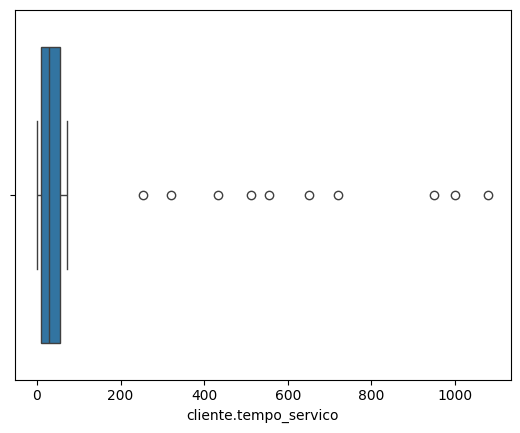

In [112]:
# Usando boxplots
import seaborn as sns

sns.boxplot(x=dados_sem_nulos['cliente.tempo_servico'])

In [113]:
q1=dados_sem_nulos['cliente.tempo_servico'].quantile(.25)# formula pra saber dos outliers
q3=q1=dados_sem_nulos['cliente.tempo_servico'].quantile(.75)
IQR= q3-q1
limite_inferior= q1-1.5*IQR
limite_superior=q3+ 1.5*IQR

In [114]:
outliers_index=(dados_sem_nulos['cliente.tempo_servico']> limite_superior) | (dados_sem_nulos['cliente.tempo_servico']<limite_inferior)

In [115]:
dados_sem_nulos[outliers_index]['cliente.tempo_servico']# achando os outliers

,cliente.tempo_servico
0,9.0
1,4.0
2,13.0
3,3.0
4,9.0
...,...
7001,13.0
7002,22.0
7003,2.0
7004,67.0


In [116]:
# Substituindo outliers, copiando o data frame pra uma nova variavel
dados_sem_out= dados_sem_nulos.copy()

In [117]:
dados_sem_out.loc[outliers_index,'cliente.tempo_servico']=np.ceil(

    dados_sem_out.loc[outliers_index,'conta.cobranca.Total']/
    dados_sem_out.loc[outliers_index,'conta.cobranca.mensal'])

<Axes: xlabel='cliente.tempo_servico'>

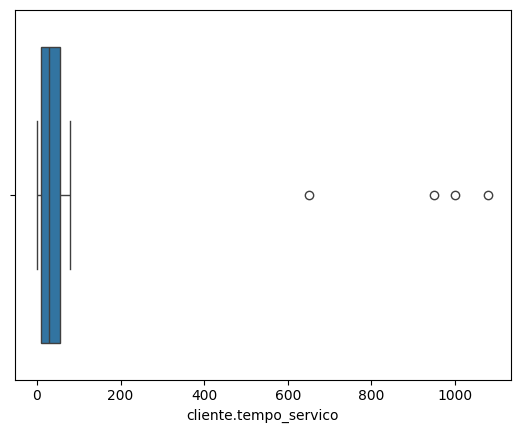

In [118]:
sns.boxplot(x=dados_sem_out.loc[outliers_index,'cliente.tempo_servico'])

### Outros métodos para detectar Outliers

Além do boxplot tradicional, existem outras abordagens estatísticas muito utilizadas para identificar pontos fora da curva em nossos dados:

#### 1) Z-score
O **Z-score** é uma medida estatística que indica a quantos desvios-padrão um determinado dado está afastado da média do grupo. Se o valor estiver muito longe da média, ele é considerado um outlier. O limite padrão mais comum para isso é de **3 desvios-padrão**.

```python
import numpy as np

# Dados de exemplo
data = np.array([10, 20, 30, 40, 150, 50, 60, 70, 80, 90, 100, 350])

# Cálculo do z-score
z_scores = (data - np.mean(data)) / np.std(data)

# Limite para considerar um dado como outlier
limite = 3

# Identificação dos outliers
outliers = data[np.abs(z_scores) > limite]

print("Outliers encontrados:", outliers)
```

---

#### 2) Regra dos 3 sigmas
A **Regra dos 3 sigmas** baseia-se nas propriedades de uma distribuição normal, onde aproximadamente **99,7% dos dados** devem estar situados dentro de um intervalo de 3 desvios-padrão para cima ou para baixo a partir da média. Valores além desse intervalo são classificados como outliers.

```python
import numpy as np

# Criar um array com os dados
dados = np.array([0, 10, 12, 13, 15, 16, 18, 20, 22, 25, 30, 35, 40, 50, 350])

# Calcular a média e o desvio padrão do conjunto de dados
media = np.mean(dados)
desvio_padrao = np.std(dados)

# Definir o limite superior e inferior para identificar os outliers
limite_superior = media + (3 * desvio_padrao)
limite_inferior = media - (3 * desvio_padrao)

# Identificar os outliers no conjunto de dados
outliers = dados[(dados > limite_superior) | (dados < limite_inferior)]

print("Outliers:", outliers)
```

---

#### 3) Análise de dispersão
A **Análise de dispersão** utiliza representações visuais rápidas para expor e isolar dados discrepantes em quartis. Ela define matematicamente os limites inferior e superior por meio de percentis correspondentes, ajudando na identificação visual de pontos fora dessas fronteiras.

```python
import matplotlib.pyplot as plt
import numpy as np

# Dados de exemplo
data = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100])

# Criação do boxplot
fig, ax = plt.subplots()
ax.boxplot(data)

# Identificação dos outliers
outliers = data[(data < np.percentile(data, 25) - (1.5 * (np.percentile(data, 75) - np.percentile(data, 25)))) |
                (data > np.percentile(data, 75) + (1.5 * (np.percentile(data, 75) - np.percentile(data, 25))))]

print("Outliers encontrados:", outliers)
```

In [119]:
#Removendo outliers corretamente separados

q1 = dados_sem_out['cliente.tempo_servico'].quantile(.25)
q3 = dados_sem_out['cliente.tempo_servico'].quantile(.75)
IQR = q3 - q1
limite_inferior = q1 - 1.5 * IQR
limite_superior = q3 + 1.5 * IQR

outliers_index = (dados_sem_out['cliente.tempo_servico'] > limite_superior) | (dados_sem_out['cliente.tempo_servico'] < limite_inferior)

In [120]:
dados_sem_out=dados_sem_out[~outliers_index]# Quero todas as amostras além das outliers, fazendo uma remoção

<Axes: xlabel='cliente.tempo_servico'>

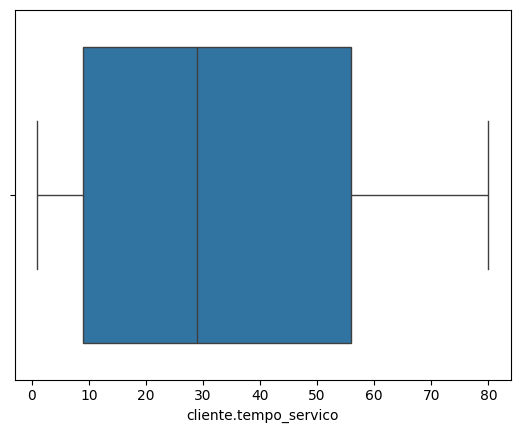

In [121]:
sns.boxplot(x=dados_sem_out['cliente.tempo_servico'])

In [123]:
dados_sem_out.reset_index(inplace=True,drop=True)

# Substituindo valores categóricos, valores que nao se pode atribuir valores numéricos


In [124]:
dados_sem_id= dados_sem_out.drop('id_cliente',axis=1).copy()

In [125]:
mapeamento={'nao':0,
            'sim':1,
            'masculino':0,
            'feminino':1

}

In [126]:
for col in dados_sem_id.columns:
  print(f"Coluna: {col}")
  print(dados_sem_id[col].unique())
  print("-" * 30)


Coluna: Churn
['nao' 'sim']
------------------------------
Coluna: cliente.genero
['masculino' 'feminino']
------------------------------
Coluna: cliente.idoso
[0 1]
------------------------------
Coluna: cliente.parceiro
['nao' 'sim']
------------------------------
Coluna: cliente.dependentes
['nao' 'sim']
------------------------------
Coluna: cliente.tempo_servico
[ 9.  4. 13.  3. 71. 63.  7. 66. 54. 72.  5. 56. 34.  1. 45. 50. 23. 55.
 26. 69. 37. 49. 67. 20. 43. 59. 12. 27.  2. 25. 29. 14. 35. 64. 39. 40.
 11.  6. 30. 70. 57. 58. 16. 32. 33. 10. 21. 61. 15. 44. 22. 24. 19. 47.
 62. 46. 52.  8. 60. 48. 28. 41. 53. 68. 31. 36. 17. 18. 65. 51. 38. 42.]
------------------------------
Coluna: telefone.servico_telefone
['sim' 'nao']
------------------------------
Coluna: telefone.varias_linhas
['sim' 'nao' 'sem servico de telefone']
------------------------------
Coluna: internet.servico_internet
['DSL' 'fibra otica' 'nao']
------------------------------
Coluna: internet.seguranca_onlin

In [129]:
colunas=['telefone.servico_telefone','Churn','cliente.parceiro','cliente.dependentes','conta.faturamente_eletronico','cliente.genero']

In [130]:
dados_sem_id[colunas]=dados_sem_id[colunas].replace(mapeamento)
dados_sem_id

/tmp/ipykernel_1772/2948753363.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dados_sem_id[colunas]=dados_sem_id[colunas].replace(mapeamento)


,Churn,cliente.genero,cliente.idoso,cliente.parceiro,cliente.dependentes,cliente.tempo_servico,telefone.servico_telefone,telefone.varias_linhas,internet.servico_internet,internet.seguranca_online,internet.backup_online,internet.protecao_dispositivo,internet.suporte_tecnico,internet.tv_streaming,internet.filmes_streaming,conta.contrato,conta.faturamente_eletronico,conta.metodo_pagamento,conta.cobranca.mensal,conta.cobranca.Total
0,0,0,0,0,0,9.0,1,sim,DSL,nao,nao,nao,nao,nao,sim,mes a mes,0,cheque pelo correio,59.90,542.40
1,1,0,0,0,0,4.0,1,nao,fibra otica,nao,nao,sim,nao,nao,nao,mes a mes,1,cheque eletronico,73.90,280.85
2,1,0,1,1,0,13.0,1,nao,fibra otica,nao,sim,sim,nao,sim,sim,mes a mes,1,cheque eletronico,98.00,1237.85
3,1,1,1,1,0,3.0,1,nao,fibra otica,nao,nao,nao,sim,sim,nao,mes a mes,1,cheque pelo correio,83.90,267.40
4,0,1,0,0,1,9.0,1,nao,DSL,nao,nao,nao,sim,sim,sim,mes a mes,1,cartao de credito (automatico),69.40,571.45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6991,0,1,0,0,0,13.0,1,nao,DSL,sim,nao,nao,sim,nao,nao,um ano,0,cheque pelo correio,55.15,742.90
6992,1,0,0,1,0,22.0,1,sim,fibra otica,nao,nao,nao,nao,nao,sim,mes a mes,1,cheque eletronico,85.10,1873.70
6993,0,0,0,0,0,2.0,1,nao,DSL,nao,sim,nao,nao,nao,nao,mes a mes,1,cheque pelo correio,50.30,92.75
6994,0,0,0,1,1,67.0,1,nao,DSL,sim,nao,sim,sim,nao,sim,dois anos,0,cheque pelo correio,67.85,4627.65


# Dummy

In [133]:
s=pd.Series(list('abca'))# vemos os valores da seguinte forma:
s

,0
0,a
1,b
2,c
3,a


In [132]:
pd.get_dummies(s)# Este metódo dummy retona um df com 3 colunas, ele pega as variaveis categóricas e coloca com os nomes dessas categorias no nosso caso, a,b e c

,a,b,c
0,True,False,False
1,False,True,False
2,False,False,True
3,True,False,False


In [134]:
dados_sem_id.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6996 entries, 0 to 6995
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Churn                          6996 non-null   int64  
 1   cliente.genero                 6996 non-null   int64  
 2   cliente.idoso                  6996 non-null   int64  
 3   cliente.parceiro               6996 non-null   int64  
 4   cliente.dependentes            6996 non-null   int64  
 5   cliente.tempo_servico          6996 non-null   float64
 6   telefone.servico_telefone      6996 non-null   int64  
 7   telefone.varias_linhas         6996 non-null   object 
 8   internet.servico_internet      6996 non-null   object 
 9   internet.seguranca_online      6996 non-null   object 
 10  internet.backup_online         6996 non-null   object 
 11  internet.protecao_dispositivo  6996 non-null   object 
 12  internet.suporte_tecnico       6996 non-null   o

In [137]:
df_dummies=pd.get_dummies(dados_sem_id).copy()

In [138]:
df_dummies.head()

,Churn,cliente.genero,cliente.idoso,cliente.parceiro,cliente.dependentes,cliente.tempo_servico,telefone.servico_telefone,conta.faturamente_eletronico,conta.cobranca.mensal,conta.cobranca.Total,...,internet.filmes_streaming_nao,internet.filmes_streaming_sem servico de internet,internet.filmes_streaming_sim,conta.contrato_dois anos,conta.contrato_mes a mes,conta.contrato_um ano,conta.metodo_pagamento_cartao de credito (automatico),conta.metodo_pagamento_cheque eletronico,conta.metodo_pagamento_cheque pelo correio,conta.metodo_pagamento_transferencia bancaria (automatica)
0,0,0,0,0,0,9.0,1,0,59.9,542.40,...,False,False,True,False,True,False,False,False,True,False
1,1,0,0,0,0,4.0,1,1,73.9,280.85,...,True,False,False,False,True,False,False,True,False,False
2,1,0,1,1,0,13.0,1,1,98.0,1237.85,...,False,False,True,False,True,False,False,True,False,False
3,1,1,1,1,0,3.0,1,1,83.9,267.40,...,True,False,False,False,True,False,False,False,True,False
4,0,1,0,0,1,9.0,1,1,69.4,571.45,...,False,False,True,False,True,False,True,False,False,False


In [139]:
df_dummies.columns

Index(['Churn', 'cliente.genero', 'cliente.idoso', 'cliente.parceiro',
       'cliente.dependentes', 'cliente.tempo_servico',
       'telefone.servico_telefone', 'conta.faturamente_eletronico',
       'conta.cobranca.mensal', 'conta.cobranca.Total',
       'telefone.varias_linhas_nao',
       'telefone.varias_linhas_sem servico de telefone',
       'telefone.varias_linhas_sim', 'internet.servico_internet_DSL',
       'internet.servico_internet_fibra otica',
       'internet.servico_internet_nao', 'internet.seguranca_online_nao',
       'internet.seguranca_online_sem servico de internet',
       'internet.seguranca_online_sim', 'internet.backup_online_nao',
       'internet.backup_online_sem servico de internet',
       'internet.backup_online_sim', 'internet.protecao_dispositivo_nao',
       'internet.protecao_dispositivo_sem servico de internet',
       'internet.protecao_dispositivo_sim', 'internet.suporte_tecnico_nao',
       'internet.suporte_tecnico_sem servico de internet',
     

In [140]:
import pandas as pd

# Criando um DataFrame de exemplo
df = pd.DataFrame({'cor': ['vermelho', 'azul', 'verde', 'vermelho'],
                   'tamanho': ['pequeno', 'médio', 'grande', 'médio'],
                   'formato': ['quadrado', 'redondo', 'redondo', 'quadrado']})

# Transformando as colunas categóricas em variáveis numéricas binárias
df_dummies = pd.get_dummies(df, columns=['cor', 'tamanho'], prefix=['cor', 'tam'], prefix_sep='-', drop_first=True)

# Exibindo o DataFrame resultante
df_dummies

,formato,cor-verde,cor-vermelho,tam-médio,tam-pequeno
0,quadrado,False,True,False,True
1,redondo,False,False,True,False
2,redondo,True,False,False,False
3,quadrado,False,True,True,False
